In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.




A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\LENOVO\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [3]:
df = pd.read_csv('set3.csv')
df.head()

,t,u,y,uv,yv
0,0.00,0.000000,0.000000,0.000000,0.000000
1,0.02,0.091960,0.000024,0.013581,0.000004
2,0.04,0.182270,0.000193,0.027177,0.000029
3,0.06,0.269337,0.000646,0.040787,0.000096
4,0.08,0.351685,0.001511,0.054406,0.000226


In [4]:
columnas = ['t', 'u', 'y', 'uv', 'yv']
faltantes = [col for col in columnas if col not in df.columns]
if faltantes:
    raise ValueError(f'Faltan en set3.csv: {faltantes}')

t = df['t'].to_numpy()
u = df['u'].to_numpy()
y = df['y'].to_numpy()
uv = df['uv'].to_numpy()
yv = df['yv'].to_numpy()

N = len(u)
if any(len(x) != N for x in (t, y, uv, yv)):
    raise ValueError('Las columnas t, u, y, uv, yv deben tener la misma longitud.')
p = round(0.8 * N)


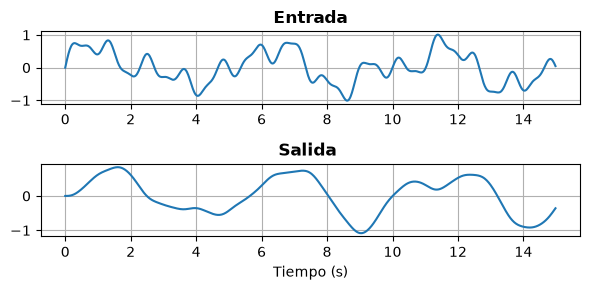

In [5]:
plt.figure(figsize=(6,3))

plt.subplot(2,1,1)
plt.plot(t,u)
plt.grid(True)
plt.title('Entrada',fontweight='bold')

plt.subplot(2,1,2)
plt.plot(t,y)
plt.grid(True)
plt.title('Salida ',fontweight='bold')
plt.xlabel('Tiempo (s)')

plt.tight_layout()
plt.show()

In [7]:
#1 Identificacion

# u empieza en cero, para que funcione desconvolucion
indices_cero = np.flatnonzero(u != 0)
if len(indices_cero) == 0:
    raise ValueError('No se puede usar desconvolución: u es completamente cero.')
k0 = int(indices_cero[0])
if not np.allclose(y[:k0], 0):
    raise ValueError('La salida no es cero antes del primer valor no nulo. No se puede usar desconvolución.')

u_desc = u[k0:]
y_desc_id = y[k0:]
y_padding = np.concatenate([y_desc_id, np.zeros(p)])
h_desc, residuo_desc = signal.deconvolve(y_padding, u_desc)

# Mínimo error cuadrático (LSE)
def LSE(t, u, y, p, N):
    T = np.mean(np.diff(t))
    UU = np.zeros((N, p))
    for i in range(p):
        if i == 0:
            UU[:, 0] = u[:N]
        else:
            UU[i:, i] = u[:N-i]
    UU *= T
    AA = UU.T @ UU
    b = UU.T @ y[:N]
    return np.linalg.solve(AA, b) * T

h_lse = LSE(t, u, y, p, N)



In [8]:
3# Predicciones con los dos sistemas ya identificados.
y_desc = signal.convolve(h_desc, u)[:N]
y_lse = signal.convolve(h_lse, u)[:N]
yv_desc = signal.convolve(h_desc, uv)[:N]
yv_lse = signal.convolve(h_lse, uv)[:N]

print(f'N = {N}, p = {p}')

N = 750, p = 600


## Punto 2.Comparación de las salidas

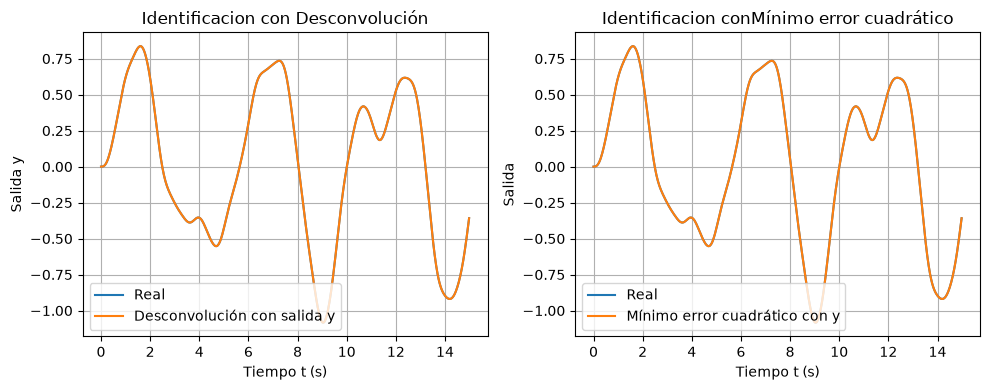

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

axs[0].plot(t, y, label='Real')
axs[0].plot(t, y_desc, label='Desconvolución con salida y')
axs[0].set_title('Identificacion con Desconvolución')
axs[0].set_xlabel('Tiempo t (s)')
axs[0].set_ylabel('Salida y')
axs[0].legend()
axs[0].grid(True)

axs[1].plot(t, y, label='Real')
axs[1].plot(t, y_lse, label='Mínimo error cuadrático con y')
axs[1].set_title('Identificacion conMínimo error cuadrático')
axs[1].set_xlabel('Tiempo t (s)')
axs[1].set_ylabel('Salida')
axs[1].legend()
axs[1].grid(True)

fig.tight_layout()
plt.show()

## Validación con uv y yv

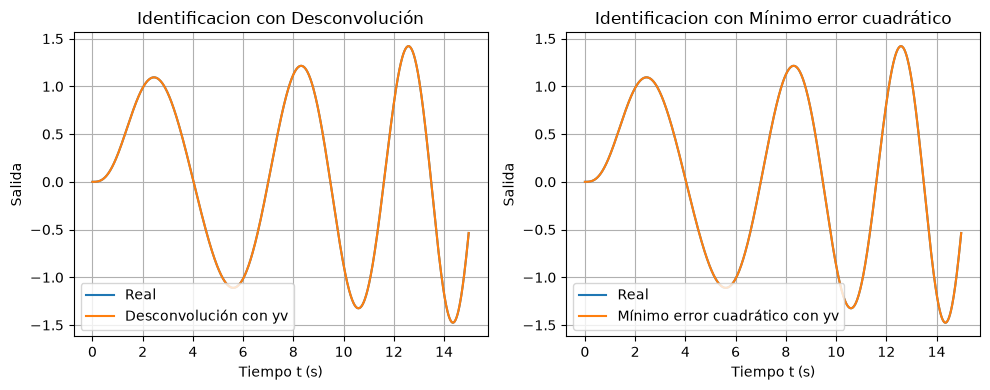

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

axs[0].plot(t, yv, label='Real')
axs[0].plot(t, yv_desc, label='Desconvolución con yv')
axs[0].set_title('Identificacion con Desconvolución')
axs[0].set_xlabel('Tiempo t (s)')
axs[0].set_ylabel('Salida')
axs[0].legend()
axs[0].grid(True)

axs[1].plot(t, yv, label='Real')
axs[1].plot(t, yv_lse, label='Mínimo error cuadrático con yv')
axs[1].set_title('Identificacion con Mínimo error cuadrático')
axs[1].set_xlabel('Tiempo t (s)')
axs[1].set_ylabel('Salida')
axs[1].legend()
axs[1].grid(True)

fig.tight_layout()
plt.show()